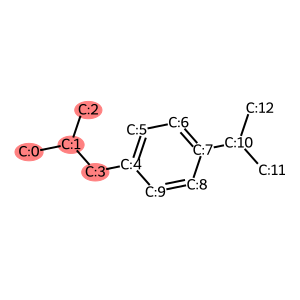

In [252]:
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem import rdmolops
from rdkit.Chem import Descriptors
from rdkit.Chem import AllChem
from copy import deepcopy

def draw_highlighted_atoms(mol, atom_ids):
    
    local_mol = deepcopy(mol)  # Create a deep copy of the molecule to avoid modifying the original
    for i, atom in enumerate(local_mol.GetAtoms()):
        # For each atom, set the property "molAtomMapNumber" to a custom number, let's say, the index of the atom in the molecule
        atom.SetProp("molAtomMapNumber", str(atom.GetIdx()))
    
    # Create a list of atom indices to highlight
    highlight_atoms = set(atom_ids)

    # Generate image with highlighted atoms
    img = Draw.MolToImage(local_mol, highlightAtoms=highlight_atoms, size=(300, 300))

    return img

# Example usage
smiles = 'CC(C)CC1=CC=C(C=C1)C(C)C'  # Target molecule
mol = Chem.MolFromSmiles(smiles)

# List of atom indices to highlight
atom_ids = [0, 1, 2, 3]

# Draw the molecule with highlighted atoms
highlighted_image = draw_highlighted_atoms(mol, atom_ids)
highlighted_image.show()  # This will display the image

In [253]:
def atom_ids_to_smarts(mol, atom_ids, reset_atom_idx = True, verbose=False):
	# Create an empty molecule and add only the atoms of interest
	q_mol = Chem.RWMol()

	# Add atoms that are in the atom_ids list to the new molecule
	atom_map = {}
	for atom_idx in atom_ids:
		atom = mol.GetAtomWithIdx(atom_idx)
		atom.SetProp("molAtomMapNumber", str(atom_idx))
		new_atom_idx = q_mol.AddAtom(atom)
		atom_map[atom_idx] = new_atom_idx

	# Now we add the bonds that correspond to the atoms in atom_ids
	for bond in mol.GetBonds():
		idx1 = bond.GetBeginAtomIdx()
		idx2 = bond.GetEndAtomIdx()

		# Check if both atoms are in the atom_ids list, if so, add the bond
		if idx1 in atom_ids and idx2 in atom_ids:
			q_mol.AddBond(atom_map[idx1], atom_map[idx2], bond.GetBondType())
	
		elif idx1 in atom_ids or idx2 in atom_ids:
			dummy_atm = AllChem.Atom(0)
			if idx1 in atom_ids:
				q_mol.AddAtom(dummy_atm)
				q_mol.AddBond(atom_map[idx1], q_mol.GetNumAtoms() - 1, bond.GetBondType())
				q_mol.GetAtomWithIdx(atom_map[idx1]).GetImplicitValence()
				q_mol.GetAtomWithIdx(atom_map[idx1]).SetNumExplicitHs(0)
				q_mol.GetAtomWithIdx(atom_map[idx1]).SetNoImplicit(False)
			else:
				q_mol.AddAtom(dummy_atm)
				q_mol.AddBond(atom_map[idx2], q_mol.GetNumAtoms() - 1, bond.GetBondType())
				q_mol.GetAtomWithIdx(atom_map[idx2]).GetImplicitValence()
				q_mol.GetAtomWithIdx(atom_map[idx2]).SetNumExplicitHs(0)
				q_mol.GetAtomWithIdx(atom_map[idx2]).SetNoImplicit(False)

	# Get the substructure as a SMILES string
	q_mol.UpdatePropertyCache()
	mw = Descriptors.ExactMolWt(q_mol)
	formula = Chem.rdMolDescriptors.CalcMolFormula(q_mol)
	substructure_smiles = Chem.MolToSmiles(q_mol, canonical=True)
	# this need newer version #ignoreAtomMapNumbers=True)
	
	#https://www.rdkit.org/docs/GettingStartedInPython.html#atom-map-indices-in-smarts
	if reset_atom_idx:
		for i, atom in enumerate(q_mol.GetAtoms()):
			# For each atom, set the property "molAtomMapNumber" to a custom number, let's say, the index of the atom in the molecule
			if atom.GetAtomicNum() != 0:
				atom.SetProp("molAtomMapNumber", str(atom.GetIdx()+1))

	substructure_smarts = Chem.MolToSmarts(q_mol)
	substructure_smarts = substructure_smarts.replace("#0","!#1")
	if verbose:
		print(f"Substructure SMARTS: {substructure_smarts}")
		print(f"Substructure Canonical SMILES: {substructure_smiles}")
		print(f"Substructure base mass: {mw}")
		print(f"Substructure formula: {formula}")
  
	return substructure_smarts,substructure_smiles,mw,formula

def match_smart_substructure(target_smiles, substructure_smiles):
	print("Target SMILES:", target_smiles)
	print("Substructure SMARTS:", substructure_smiles)
	target_mol = Chem.MolFromSmiles(target_smiles)
	#Chem.SanitizeMol(target_mol)
	qmol = Chem.MolFromSmarts(substructure_smiles)

	ind_map = {}
	for atom in qmol.GetAtoms() :
		map_num = atom.GetAtomMapNum()
		if map_num:
			ind_map[map_num-1] = atom.GetIdx()
	
	map_list = [ind_map[x] for x in sorted(ind_map)]
	matches = []
	for match in target_mol.GetSubstructMatches( qmol ) :
		mas = [match[x] for x in map_list]
		matches.append(mas)
	
	return matches

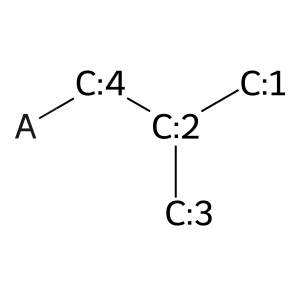

Target SMILES: CC(C)CC1=CC=C(C=C1)C(C)C
Substructure SMARTS: [#6:1]-[#6:2](-[#6:3])-[#6:4]-[!#1]
Substructure Matches: [[0, 1, 2, 3]]


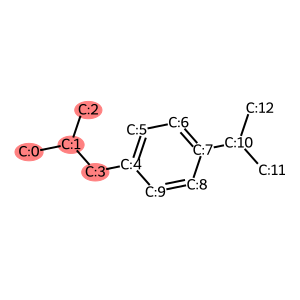

In [254]:
# Example usage
target_smiles = 'CC(C)CC1=CC=C(C=C1)C(C)C'  # Target molecule
mol = Chem.MolFromSmiles(target_smiles)
# Kekulize the molecule (convert aromatic bonds to single and double bonds)
#Chem.Kekulize(mol, clearAromaticFlags=True)
# Optionally, sanitize the molecule
# Chem.SanitizeMol(mol)

# List of atom indices to form the substructure
atom_ids = [0, 1, 2, 3]

# Extract substructure from atom indices
substructure_smart,_,_,_ = atom_ids_to_smarts(mol, atom_ids)
#substructure_smart = substructure_smart.replace('[#0]', '[*]')
sub_mol = Chem.MolFromSmarts(substructure_smart)
img = Draw.MolToImage(sub_mol,  size=(300, 300))
img.show() # This will display the image of the substructure

# Perform substructure match with the target molecule
#substructure_smart = '[#6:1]-[#6:2](-[#6:3])-[#6:4]-[*:5]'
matches = match_smart_substructure(target_smiles, substructure_smart)
print("Substructure Matches:", matches)

atom_ids = matches[0]
highlighted_image = draw_highlighted_atoms(mol, atom_ids)
highlighted_image.show()  # This will display the image

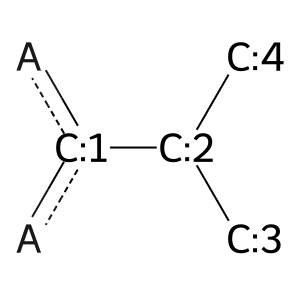

Target SMILES: CC(C)CC1=CC=C(C=C1)C(C)C
Substructure SMARTS: [#6:1](-[#6:2](-[#6:3])-[#6:4])(:[!#1]):[!#1]
Substructure Matches: [[7, 10, 11, 12]]


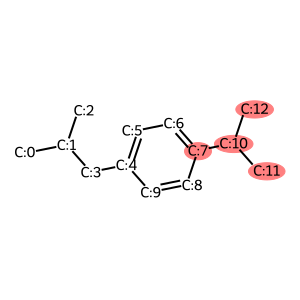

In [255]:
# Extract substructure from atom indices
atom_ids = [7, 10, 11, 12]
substructure_smart,_,_,_ = atom_ids_to_smarts(mol, atom_ids)

sub_mol = Chem.MolFromSmarts(substructure_smart)
img = Draw.MolToImage(sub_mol,  size=(300, 300))
img.show()  # This will display the image of the substructure

# Perform substructure match with the target molecule
matches = match_smart_substructure(target_smiles, substructure_smart)
print("Substructure Matches:", matches)
if len(matches) > 0:
    atom_ids = matches[0]
    highlighted_image = draw_highlighted_atoms(mol, atom_ids)
    highlighted_image.show()  # This will display the image

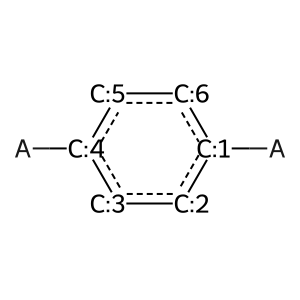

Target SMILES: CC(C)CC1=CC=C(C=C1)C(C)C
Substructure SMARTS: [#6:1]1(:[#6:2]:[#6:3]:[#6:4](:[#6:5]:[#6:6]:1)-[!#1])-[!#1]
Substructure Matches: [[4, 5, 6, 7, 8, 9]]


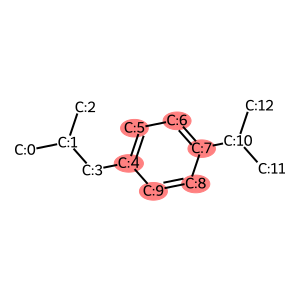

In [256]:
# Extract substructure from atom indices
atom_ids = [4, 5, 6, 7, 8,9]
substructure_smart,_,_,_ = atom_ids_to_smarts(mol, atom_ids)

sub_mol = Chem.MolFromSmarts(substructure_smart)
img = Draw.MolToImage(sub_mol,  size=(300, 300))
img.show()  # This will display the image of the substructure

# Perform substructure match with the target molecule
matches = match_smart_substructure(target_smiles, substructure_smart)
print("Substructure Matches:", matches)
if len(matches) > 0:
    atom_ids = matches[0]
    highlighted_image = draw_highlighted_atoms(mol, atom_ids)
    highlighted_image.show()  # This will display the image

In [257]:
import numpy as np
from scipy.sparse.csgraph import connected_components
from scipy.sparse import csr_matrix

def remove_atoms_and_group_by_connected(adj_matrix, atom_ids_to_remove):
    """
    Removes specified atom IDs from the adjacency matrix and groups the remaining atoms by connected components.

    Parameters:
        adj_matrix (np.array): The adjacency matrix of the molecule.
        atom_ids_to_remove (list): List of atom indices to be removed from the matrix.

    Returns:
        List of connected components: Each component is a list of atom indices.
    """
    adj_matrix = adj_matrix.copy()  # Create a copy of the adjacency matrix to avoid modifying the original
    # Remove rows and columns corresponding to the atoms to be removed
    for atom_id in atom_ids_to_remove:
        adj_matrix[:, atom_id] = 0  # Set the column to zero
        adj_matrix[atom_id, :] = 0 # Set the row to zero
        
    # Convert the updated adjacency matrix to a sparse CSR matrix for efficient computation
    sparse_matrix = csr_matrix(adj_matrix)

    # Use scipy's connected_components to find the connected components in the graph
    num_components, labels = connected_components(sparse_matrix, directed=False, return_labels=True)

    # Group atom indices by connected components
    connected_atom_ids = [np.where(labels == i)[0].tolist() for i in range(num_components)]
    connected_atom_ids = [ tuple(atom_ids) for atom_ids in connected_atom_ids if atom_ids[0] not in set(atom_ids_to_remove)]
  
    return connected_atom_ids

In [ ]:

from rdkit import Chem

def match_smart_substructure_with_remaiders(target_smiles, substructure_smart):
	"""
	Matches a SMARTS substructure with atom mapping to a target SMILES molecule,
	and returns the rest of the atom index sets grouped by disconnected fragments.

	Parameters:
		target_smiles (str): The SMILES of the molecule to search in.
		substructure_smiles (str): The SMARTS pattern with atom map numbers.

	Returns:
		matches (list of lists): Atom indices in target molecule corresponding to SMARTS-mapped atoms.
		remainders (list of lists of lists): For each match, a list of fragments,
											 each fragment is a list of atom indices.
	"""

	print("Target SMILES:", target_smiles)
	print("Substructure SMARTS:", substructure_smart)
	target_mol = Chem.MolFromSmiles(target_smiles)
 
	qmol = Chem.MolFromSmarts(substructure_smart)
	matches = []

	ind_map = {} # map atom numbers to indices
	for atom in qmol.GetAtoms() :
		map_num = atom.GetAtomMapNum()
		if map_num:
			ind_map[map_num-1] = atom.GetIdx()
	
	map_list = [ind_map[x] for x in sorted(ind_map)] # qmol atom indices list to match

	for match in target_mol.GetSubstructMatches( qmol ) :
		mas = tuple([match[x] for x in map_list])
		matches.append(mas)

	# get remainders
	remainders = []
	adj_matrix = Chem.rdmolops.GetAdjacencyMatrix(target_mol)
	all_atoms = set(range(target_mol.GetNumAtoms()))

	for match in matches:
		# Compute unmatched atom indices
		unmatched_atoms = list(all_atoms - set(match))

		if not unmatched_atoms:
			continue
		remainders = remove_atoms_and_group_by_connected(adj_matrix, atom_ids_to_remove=match)

	return matches, remainders

matches, remainders = match_smart_substructure_with_remaiders(target_smiles, substructure_smart)
print("Substructure Matches:", matches)
print("Remainders:", remainders)

Target SMILES: CC(C)CC1=CC=C(C=C1)C(C)C
Substructure SMARTS: [#6:1]1(:[#6:2]:[#6:3]:[#6:4](:[#6:5]:[#6:6]:1)-[!#1])-[!#1]
Substructure Matches: [(4, 5, 6, 7, 8, 9)]
Remainders: [(0, 1, 2, 3), (10, 11, 12)]


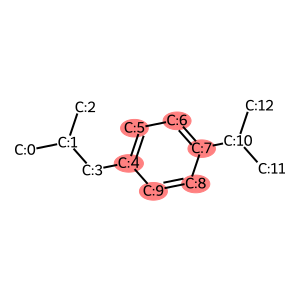

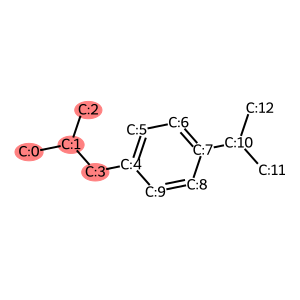

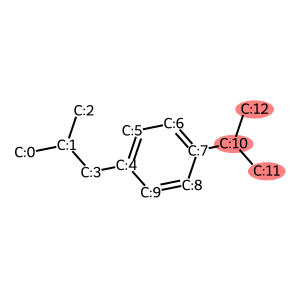

In [262]:
for match in matches:
    atom_ids = match
    highlighted_image = draw_highlighted_atoms(mol, atom_ids)
    highlighted_image.show()  # This will display the image

for match in remainders:
    atom_ids = match
    highlighted_image = draw_highlighted_atoms(mol, atom_ids)
    highlighted_image.show()  # This will display the image

In [260]:
original = [[1, 2], [3, 4], [1, 2], [5, 6]]

# Convert each sublist to a tuple, use set to remove duplicates, then convert back to list
deduplicated = [list(item) for item in set(tuple(sublist) for sublist in original)]

print(deduplicated)


[[1, 2], [3, 4], [5, 6]]


In [261]:
original = [(1, 2), (3, 4), (1, 2), (5, 6)]
set(original)  # This will remove duplicates

{(1, 2), (3, 4), (5, 6)}